In [104]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
from tensorflow.keras.layers import Dense, Dropout

In [4]:
data=pd.read_csv('/kaggle/input/datasets/emadhamdy11111/car-parshing/car_purchasing.csv',encoding='latin1')

In [5]:
data.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248


In [16]:
data.shape

(500, 9)

In [6]:
data.duplicated().sum()

np.int64(0)

In [7]:
data.isna().sum()

customer name          0
customer e-mail        0
country                0
gender                 0
age                    0
annual Salary          0
credit card debt       0
net worth              0
car purchase amount    0
dtype: int64

In [8]:
data.dtypes

customer name           object
customer e-mail         object
country                 object
gender                   int64
age                    float64
annual Salary          float64
credit card debt       float64
net worth              float64
car purchase amount    float64
dtype: object

In [10]:
data.columns=data.columns.str.strip()

In [17]:
data=data.drop(columns=['customer name','customer e-mail'])

In [22]:
data['country']=data['country'].astype(str).str.lower().str.strip()

data['country'].unique()

array(['bulgaria', 'belize', 'algeria', 'cook islands', 'brazil',
       'liberia', 'syria', 'czech republic', 'armenia', 'somalia',
       'sint maarten', 'greenland', 'nicaragua', 'palestine, state of',
       'united arab emirates', 'gabon', 'tokelau', 'portugal', 'chad',
       'iraq', 'sudan', 'angola', 'nigeria', 'madagascar', 'macedonia',
       'oman', 'colombia', 'namibia', 'denmark', 'dominican republic',
       'costa rica', 'botswana', 'saint pierre and miquelon', 'france',
       'senegal', 'cambodia', 'suriname', 'turkey', 'ethiopia',
       'french guiana', 'bhutan', 'georgia', 'mozambique', 'nauru',
       'timor-leste', 'djibouti', 'argentina', 'taiwan', 'åland islands',
       'turks and caicos islands', 'samoa', 'vanuatu', 'mongolia',
       'sri lanka', 'guinea-bissau', 'egypt', 'slovenia', 'benin',
       'cape verde', 'paraguay', 'laos', 'iceland', 'viet nam',
       'marshall islands', 'germany', 'kyrgyzstan', 'mauritius', 'gambia',
       'reunion', 'jordan', 's

In [27]:
data.dtypes

country                 object
gender                   int64
age                    float64
annual Salary          float64
credit card debt       float64
net worth              float64
car purchase amount    float64
dtype: object

In [29]:
data['country']=data['country'].astype('string')

In [30]:
data.dtypes

country                string[python]
gender                          int64
age                           float64
annual Salary                 float64
credit card debt              float64
net worth                     float64
car purchase amount           float64
dtype: object

In [34]:
data_encoded = pd.get_dummies(data, columns=['country'], drop_first=True)

In [37]:
X = data_encoded.drop(columns=['car purchase amount'])
y = data_encoded['car purchase amount']

scaler= StandardScaler()
x_scaled= scaler.fit_transform(X)

In [40]:
pca=PCA(n_components=0.95)
X_pca = pca.fit_transform(x_scaled)

X_pca.shape

(500, 200)

In [41]:
y.shape

(500,)

In [44]:
x_train_val,x_test,y_train_val,y_test=train_test_split(X_pca,y,random_state=42,test_size=0.2)

In [45]:
x_train,x_val,y_train,y_val=train_test_split(x_train_val,y_train_val,test_size=42,random_state=42)


In [95]:
scaler_x=StandardScaler()
x_train_scaled=scaler_x.fit_transform(x_train)
x_val_scaled=scaler_x.transform(x_val)
x_test_scaled=scaler_x.transform(x_test)

In [66]:
print("x_train_scaled:", x_train_scaled.shape)
print("y_train:", y_train.shape)
print("x_val_scaled:", x_val_scaled.shape)
print("y_val:", y_val.shape)



x_train_scaled: (358, 200)
y_train: (358,)
x_val_scaled: (42, 200)
y_val: (42,)


In [96]:
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1))

y_val_scaled = scaler_y.transform(y_val.to_numpy().reshape(-1, 1))

y_test_scaled = scaler_y.transform(y_test.to_numpy().reshape(-1, 1))

In [114]:
model = tf.keras.Sequential([
    Dense(32, activation='relu', input_shape=(x_train_scaled.shape[1],)), 
    Dropout(0.2),
    Dense(1) 
])

In [115]:
model.compile(
    optimizer='adam',
    loss='mse'
) 

In [118]:
early_stop=EarlyStopping(
    restore_best_weights=True,
    patience=5,
    monitor='val_loss'
)

In [119]:
print(y_train_scaled[:5])

[[ 1.19312832]
 [-1.38293281]
 [ 1.8523514 ]
 [-0.44743863]
 [-0.09648331]]


In [120]:
history=model.fit(
    x_train_scaled,
    y_train_scaled,
    validation_data=(x_val_scaled,y_val_scaled),
    callbacks=[early_stop],
    epochs=200,
    batch_size=32,
    verbose=1
)

Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - loss: 3.0431 - val_loss: 2.2475
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2.0695 - val_loss: 1.9762
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.3887 - val_loss: 1.8047
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0292 - val_loss: 1.6700
Epoch 5/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9449 - val_loss: 1.5955
Epoch 6/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9217 - val_loss: 1.5150
Epoch 7/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9962 - val_loss: 1.4790
Epoch 8/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.8649 - val_loss: 1.4077
Epoch 9/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6478 - val_loss: 1.3595
Epoch 10/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.7138 - val_loss: 1.3433
Epoch 11/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6547 - val_loss: 1.2999
Epoch 12/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - 

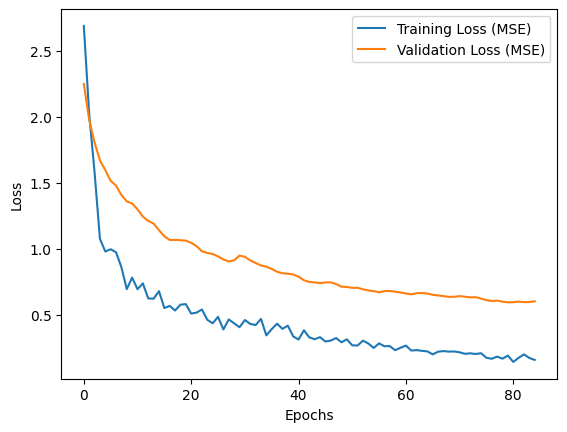

In [121]:
plt.plot(history.history['loss'], label='Training Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [123]:
y_pred_scaled= model.predict(x_test_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Mean Absolute Error (MAE): 6132.27109655
R2 Score: 0.37163140443219855
